In [4]:
!pip install scikit-optimize


[notice] A new release of pip is available: 24.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [7]:
import sys
!{sys.executable} -m pip install scikit-optimize

  Using cached scikit_optimize-0.10.2-py2.py3-none-any.whl.metadata (9.7 kB)
  Using cached pyaml-26.7.0-py3-none-any.whl.metadata (12 kB)
Using cached scikit_optimize-0.10.2-py2.py3-none-any.whl (107 kB)
Using cached pyaml-26.7.0-py3-none-any.whl (27 kB)

   -------------------- ------------------- 1/2 [scikit-optimize]
   ---------------------------------------- 2/2 [scikit-optimize]



  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


In [8]:
# ==========================================================
# SUPERCONDUCTOR CRITICAL TEMPERATURE PREDICTION
# DECISION TREE HYPERPARAMETER OPTIMIZATION USING BO, GA AND PSO
# + EXPLAINABILITY (Feature Importance, Permutation Importance, SHAP)
# ==========================================================

import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
from skopt import gp_minimize
from skopt.space import Real

warnings.filterwarnings("ignore")

In [1]:
# ==========================================================
# 1. CONFIGURATION
# ==========================================================

# >>> CHANGE THIS PATH TO YOUR OWN train.csv <<<
DATA_PATH = r"C:\Users\keert\OneDrive\Desktop\DT_CODES\train.csv"

TARGET = "critical_temp"
SEED = 42

# Equal budget: 24 objective evaluations per optimizer (same as GPR code)
BO_CALLS = 24
GA_POPULATION = 6
GA_GENERATIONS = 3
PSO_PARTICLES = 6
PSO_ITERATIONS = 3

In [9]:
# ==========================================================
# 2. LOAD DATA AND SPLIT (same 70/15/15 split as GPR)
# ==========================================================

df = pd.read_csv(DATA_PATH)

print("=" * 60)
print("DECISION TREE HYPERPARAMETER OPTIMIZATION")
print("=" * 60)
print("Dataset shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())

if df.isnull().sum().sum() > 0:
    raise ValueError("Dataset contains missing values. Handle them first.")

X = df.drop(TARGET, axis=1)
y = df[TARGET]
feature_names = X.columns.tolist()

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=SEED
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=SEED
)

print("\nTraining samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Test samples:", len(X_test))

# NOTE: Decision trees don't need feature scaling, so no StandardScaler.
# Trees are cheap to fit, so we tune on the FULL train set and
# evaluate on the FULL validation set (no subsets needed like GPR).

DECISION TREE HYPERPARAMETER OPTIMIZATION
Dataset shape: (21263, 82)
Missing values: 0

Training samples: 14884
Validation samples: 3189
Test samples: 3190


In [10]:
# ==========================================================
# 3. HYPERPARAMETER SEARCH SPACE
# ==========================================================

# Continuous encoding (optimizers work on floats), decoded to real values:
# [max_depth, min_samples_split, min_samples_leaf, max_features, log10(ccp_alpha)]

LOWER = np.array([2.0,  2.0,  1.0, 0.10, -6.0])
UPPER = np.array([30.0, 50.0, 30.0, 1.00, -1.0])


def decode_params(params):
    """Convert continuous coordinates into actual hyperparameters."""
    return {
        "max_depth": int(round(params[0])),
        "min_samples_split": int(round(params[1])),
        "min_samples_leaf": int(round(params[2])),
        "max_features": float(params[3]),
        "ccp_alpha": float(10 ** params[4]),
    }


def build_model(p):
    return DecisionTreeRegressor(
        max_depth=p["max_depth"],
        min_samples_split=p["min_samples_split"],
        min_samples_leaf=p["min_samples_leaf"],
        max_features=p["max_features"],
        ccp_alpha=p["ccp_alpha"],
        random_state=SEED,
    )


def objective(params):
    """Minimize RMSE on the validation set."""
    p = decode_params(params)
    try:
        model = build_model(p)
        model.fit(X_train, y_train)
        pred = model.predict(X_val)
        rmse = np.sqrt(mean_squared_error(y_val, pred))
        if not np.isfinite(rmse):
            return 1e10
        return float(rmse)
    except (ValueError, FloatingPointError):
        return 1e10

In [11]:
# ==========================================================
# 4. BAYESIAN OPTIMIZATION (BO)
# ==========================================================

print("\n" + "=" * 60)
print("BAYESIAN OPTIMIZATION")
print("=" * 60)

start = time.time()

bo_result = gp_minimize(
    func=objective,
    dimensions=[
        Real(LOWER[0], UPPER[0], name="max_depth"),
        Real(LOWER[1], UPPER[1], name="min_samples_split"),
        Real(LOWER[2], UPPER[2], name="min_samples_leaf"),
        Real(LOWER[3], UPPER[3], name="max_features"),
        Real(LOWER[4], UPPER[4], name="log_ccp_alpha"),
    ],
    n_calls=BO_CALLS,
    n_initial_points=8,
    random_state=SEED,
)

bo_time = time.time() - start
bo_params = np.array(bo_result.x)
bo_rmse = float(bo_result.fun)

print("Best BO RMSE:", round(bo_rmse, 4))
print("Best BO parameters:", decode_params(bo_params))
print("BO runtime:", round(bo_time, 2), "seconds")


BAYESIAN OPTIMIZATION
Best BO RMSE: 11.0047
Best BO parameters: {'max_depth': 21, 'min_samples_split': 24, 'min_samples_leaf': 1, 'max_features': 0.9479815801163677, 'ccp_alpha': 0.0006553013900933989}
BO runtime: 18.95 seconds


In [12]:
# ==========================================================
# 5. GENETIC ALGORITHM (GA)
# ==========================================================

def genetic_algorithm():
    local_rng = np.random.default_rng(SEED)
    span = UPPER - LOWER

    population = local_rng.uniform(
        LOWER, UPPER, size=(GA_POPULATION, len(LOWER))
    )
    scores = np.array([objective(ind) for ind in population])

    best_idx = np.argmin(scores)
    best_params = population[best_idx].copy()
    best_score = float(scores[best_idx])

    for generation in range(GA_GENERATIONS):
        new_population = [best_params.copy()]  # elitism

        while len(new_population) < GA_POPULATION:
            # Tournament selection
            c = local_rng.choice(GA_POPULATION, size=3, replace=False)
            parent1 = population[c[np.argmin(scores[c])]]
            c = local_rng.choice(GA_POPULATION, size=3, replace=False)
            parent2 = population[c[np.argmin(scores[c])]]

            # Crossover
            w = local_rng.random()
            child = w * parent1 + (1 - w) * parent2

            # Mutation (scaled to each parameter's range)
            mask = local_rng.random(len(LOWER)) < 0.30
            if mask.any():
                child[mask] += local_rng.normal(
                    0, 0.15, size=mask.sum()
                ) * span[mask]

            child = np.clip(child, LOWER, UPPER)
            new_population.append(child)

        population = np.array(new_population)
        scores = np.array([objective(ind) for ind in population])

        gen_best = np.argmin(scores)
        if scores[gen_best] < best_score:
            best_score = float(scores[gen_best])
            best_params = population[gen_best].copy()

        print(f"GA Generation {generation + 1}: Best RMSE = {best_score:.4f}")

    return best_params, best_score


print("\n" + "=" * 60)
print("GENETIC ALGORITHM")
print("=" * 60)

start = time.time()
ga_params, ga_rmse = genetic_algorithm()
ga_time = time.time() - start

print("Best GA RMSE:", round(ga_rmse, 4))
print("Best GA parameters:", decode_params(ga_params))
print("GA runtime:", round(ga_time, 2), "seconds")


GENETIC ALGORITHM
GA Generation 1: Best RMSE = 11.9216
GA Generation 2: Best RMSE = 11.5615
GA Generation 3: Best RMSE = 11.5615
Best GA RMSE: 11.5615
Best GA parameters: {'max_depth': 15, 'min_samples_split': 47, 'min_samples_leaf': 15, 'max_features': 0.840485451943747, 'ccp_alpha': 0.00015022218723678785}
GA runtime: 13.64 seconds


In [13]:
# ==========================================================
# 6. PARTICLE SWARM OPTIMIZATION (PSO)
# ==========================================================

def particle_swarm():
    local_rng = np.random.default_rng(SEED)

    positions = local_rng.uniform(
        LOWER, UPPER, size=(PSO_PARTICLES, len(LOWER))
    )
    velocities = np.zeros_like(positions)

    personal_best = positions.copy()
    personal_scores = np.array([objective(p) for p in positions])

    idx = np.argmin(personal_scores)
    global_best = personal_best[idx].copy()
    global_score = float(personal_scores[idx])

    inertia, cognitive, social = 0.7, 1.5, 1.5

    for iteration in range(PSO_ITERATIONS):
        for i in range(PSO_PARTICLES):
            r1 = local_rng.random(len(LOWER))
            r2 = local_rng.random(len(LOWER))

            velocities[i] = (
                inertia * velocities[i]
                + cognitive * r1 * (personal_best[i] - positions[i])
                + social * r2 * (global_best - positions[i])
            )
            positions[i] = np.clip(positions[i] + velocities[i], LOWER, UPPER)

            score = objective(positions[i])

            if score < personal_scores[i]:
                personal_scores[i] = score
                personal_best[i] = positions[i].copy()

            if score < global_score:
                global_score = float(score)
                global_best = positions[i].copy()

        print(f"PSO Iteration {iteration + 1}: Best RMSE = {global_score:.4f}")

    return global_best, global_score


print("\n" + "=" * 60)
print("PARTICLE SWARM OPTIMIZATION")
print("=" * 60)

start = time.time()
pso_params, pso_rmse = particle_swarm()
pso_time = time.time() - start

print("Best PSO RMSE:", round(pso_rmse, 4))
print("Best PSO parameters:", decode_params(pso_params))
print("PSO runtime:", round(pso_time, 2), "seconds")


PARTICLE SWARM OPTIMIZATION
PSO Iteration 1: Best RMSE = 11.3231
PSO Iteration 2: Best RMSE = 11.3231
PSO Iteration 3: Best RMSE = 11.0468
Best PSO RMSE: 11.0468
Best PSO parameters: {'max_depth': 22, 'min_samples_split': 35, 'min_samples_leaf': 1, 'max_features': 0.8454386679526782, 'ccp_alpha': 2.724565298431443e-05}
PSO runtime: 16.11 seconds


In [14]:
# ==========================================================
# 7. COMPARE ALL THREE OPTIMIZERS
# ==========================================================

comparison = pd.DataFrame([
    {"Model": "DecisionTree", "Method": "BO", "Tuning_Validation_RMSE": bo_rmse,
     "Runtime_seconds": bo_time, **decode_params(bo_params)},
    {"Model": "DecisionTree", "Method": "GA", "Tuning_Validation_RMSE": ga_rmse,
     "Runtime_seconds": ga_time, **decode_params(ga_params)},
    {"Model": "DecisionTree", "Method": "PSO", "Tuning_Validation_RMSE": pso_rmse,
     "Runtime_seconds": pso_time, **decode_params(pso_params)},
])

comparison.to_csv("DT_Optimization_Comparison.csv", index=False)

print("\nOPTIMIZER COMPARISON")
print(comparison.to_string(index=False))

# Select using validation RMSE only, never test RMSE
results = [("BO", bo_rmse, bo_params),
           ("GA", ga_rmse, ga_params),
           ("PSO", pso_rmse, pso_params)]

best_method, best_tuning_rmse, best_params = min(results, key=lambda r: r[1])
best_values = decode_params(best_params)

print("\nSelected optimizer:", best_method)
print("Selected parameters:", best_values)


OPTIMIZER COMPARISON
       Model Method  Tuning_Validation_RMSE  Runtime_seconds  max_depth  min_samples_split  min_samples_leaf  max_features  ccp_alpha
DecisionTree     BO               11.004663        18.947838         21                 24                 1      0.947982   0.000655
DecisionTree     GA               11.561542        13.638808         15                 47                15      0.840485   0.000150
DecisionTree    PSO               11.046806        16.108539         22                 35                 1      0.845439   0.000027

Selected optimizer: BO
Selected parameters: {'max_depth': 21, 'min_samples_split': 24, 'min_samples_leaf': 1, 'max_features': 0.9479815801163677, 'ccp_alpha': 0.0006553013900933989}


In [15]:
# ==========================================================
# 8. BASELINE (DEFAULT) DECISION TREE FOR COMPARISON
# ==========================================================

dt_baseline = DecisionTreeRegressor(random_state=SEED)
dt_baseline.fit(X_train, y_train)
base_pred = dt_baseline.predict(X_test)

base_mae = mean_absolute_error(y_test, base_pred)
base_rmse = np.sqrt(mean_squared_error(y_test, base_pred))
base_r2 = r2_score(y_test, base_pred)

print("\nBASELINE (default) DT TEST RESULTS")
print("MAE :", round(base_mae, 4))
print("RMSE:", round(base_rmse, 4))
print("R²  :", round(base_r2, 4))


BASELINE (default) DT TEST RESULTS
MAE : 6.6592
RMSE: 12.9892
R²  : 0.8534


In [16]:
# ==========================================================
# 9. FIT THE SELECTED OPTIMIZED MODEL
# ==========================================================

dt_optimized = build_model(best_values)
print("\nFitting final optimized Decision Tree...")
dt_optimized.fit(X_train, y_train)


Fitting final optimized Decision Tree...


,criterion,'squared_error'
,splitter,'best'
,max_depth,21
,min_samples_split,24
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,0.9479815801163677
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,ccp_alpha,0.0006553013900933989


In [17]:
# ==========================================================
# 10. VALIDATION + TEST EVALUATION
# ==========================================================

y_val_pred = dt_optimized.predict(X_val)
val_mae = mean_absolute_error(y_val, y_val_pred)
val_rmse = np.sqrt(mean_squared_error(y_val, y_val_pred))
val_r2 = r2_score(y_val, y_val_pred)

print("\nFULL VALIDATION RESULTS")
print("MAE :", round(val_mae, 4))
print("RMSE:", round(val_rmse, 4))
print("R²  :", round(val_r2, 4))

y_test_pred = dt_optimized.predict(X_test)
test_mae = mean_absolute_error(y_test, y_test_pred)
test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred))
test_r2 = r2_score(y_test, y_test_pred)

print("\nFINAL TEST RESULTS")
print("Selected optimizer:", best_method)
print("MAE :", round(test_mae, 4))
print("RMSE:", round(test_rmse, 4))
print("R²  :", round(test_r2, 4))


FULL VALIDATION RESULTS
MAE : 6.194
RMSE: 11.0047
R²  : 0.8965

FINAL TEST RESULTS
Selected optimizer: BO
MAE : 6.9149
RMSE: 12.5279
R²  : 0.8636


In [18]:
# ==========================================================
# 11. SAVE FINAL RESULTS
# ==========================================================

final_metrics = pd.DataFrame([{
    "Model": "DecisionTree",
    "Selected_Optimizer": best_method,
    "Tuning_Validation_RMSE": best_tuning_rmse,
    "Validation_MAE": val_mae,
    "Validation_RMSE": val_rmse,
    "Validation_R2": val_r2,
    "Test_MAE": test_mae,
    "Test_RMSE": test_rmse,
    "Test_R2": test_r2,
    "Baseline_Test_RMSE": base_rmse,
    "Baseline_Test_R2": base_r2,
    "Tree_Depth": dt_optimized.get_depth(),
    "Num_Leaves": dt_optimized.get_n_leaves(),
}])
final_metrics.to_csv("DT_Optimized_Final_Metrics.csv", index=False)

pd.DataFrame({
    "Actual": y_test.to_numpy(),
    "Predicted": y_test_pred,
}).to_csv("DT_Optimized_Predictions.csv", index=False)

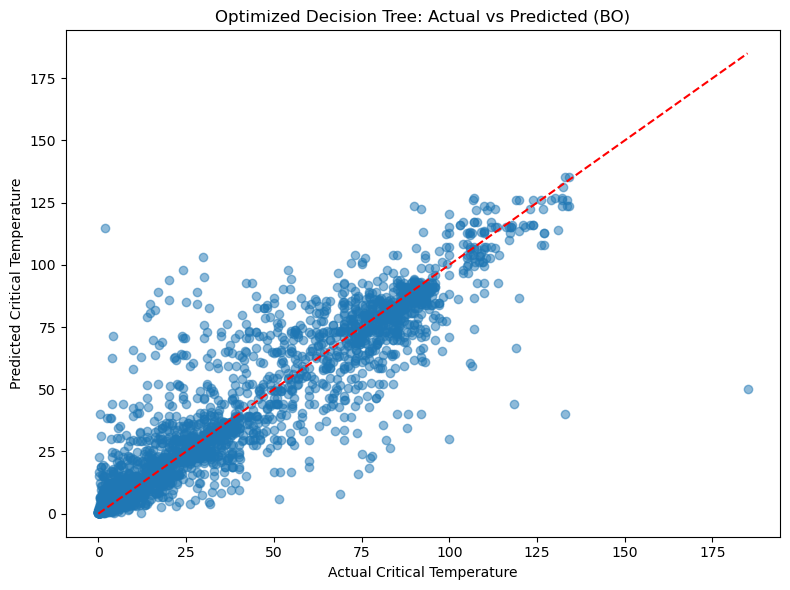

In [19]:
# ==========================================================
# 12. ACTUAL VS PREDICTED PLOT
# ==========================================================

plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_test_pred, alpha=0.5)
low = min(float(y_test.min()), float(y_test_pred.min()))
high = max(float(y_test.max()), float(y_test_pred.max()))
plt.plot([low, high], [low, high], "r--")
plt.xlabel("Actual Critical Temperature")
plt.ylabel("Predicted Critical Temperature")
plt.title(f"Optimized Decision Tree: Actual vs Predicted ({best_method})")
plt.tight_layout()
plt.savefig("DT_Optimized_Actual_vs_Predicted.png", dpi=300)
plt.show()

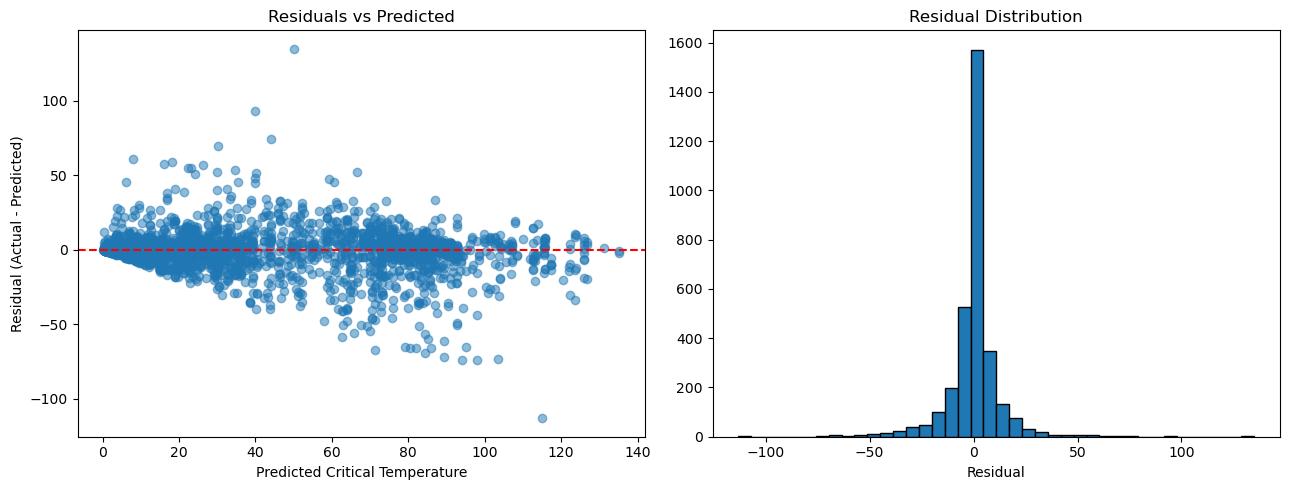

In [20]:
# ==========================================================
# 12b. RESIDUALS PLOT
# ==========================================================
residuals = y_test.to_numpy() - y_test_pred

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].scatter(y_test_pred, residuals, alpha=0.5)
ax[0].axhline(0, color="r", linestyle="--")
ax[0].set_xlabel("Predicted Critical Temperature")
ax[0].set_ylabel("Residual (Actual - Predicted)")
ax[0].set_title("Residuals vs Predicted")
ax[1].hist(residuals, bins=40, edgecolor="black")
ax[1].set_xlabel("Residual")
ax[1].set_title("Residual Distribution")
plt.tight_layout()
plt.savefig("DT_Optimized_Residuals.png", dpi=300)
plt.show()


EXPLAINABILITY

Top 10 features (impurity-based):
range_ThermalConductivity          0.5594
wtd_gmean_ThermalConductivity      0.1259
std_atomic_mass                    0.0357
wtd_gmean_Valence                  0.0352
wtd_std_ElectronAffinity           0.0169
wtd_mean_ThermalConductivity       0.0159
wtd_entropy_ThermalConductivity    0.0157
wtd_range_Valence                  0.0151
mean_Density                       0.0129
entropy_Density                    0.0102


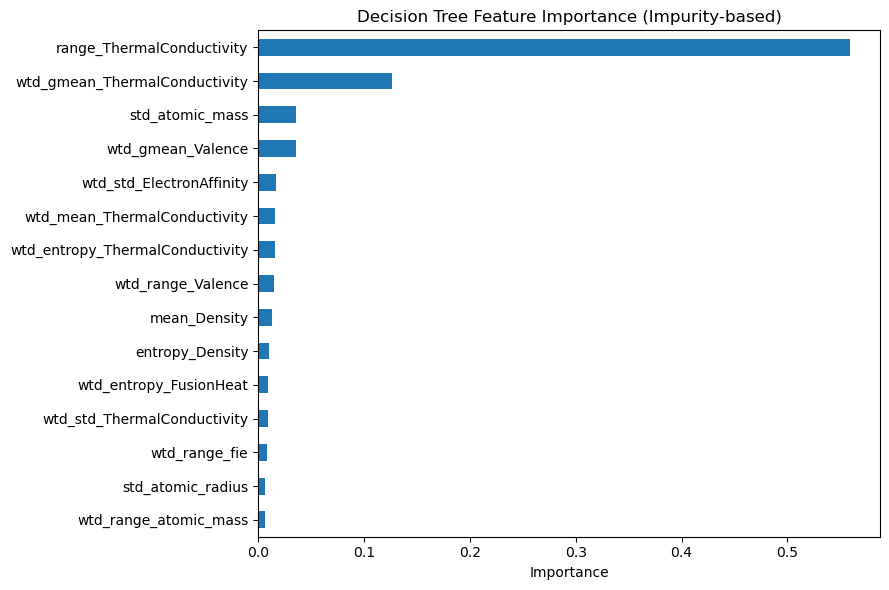


Top 10 features (permutation):
                        Feature  Mean_Importance    Std
      range_ThermalConductivity          20.0959 0.3013
  wtd_gmean_ThermalConductivity           8.4733 0.3340
              wtd_gmean_Valence           5.7692 0.3024
                std_atomic_mass           5.4397 0.2489
         wtd_entropy_FusionHeat           4.7511 0.3554
           wtd_mean_atomic_mass           4.5220 0.3239
       wtd_std_ElectronAffinity           4.3699 0.2589
              wtd_range_Valence           4.3252 0.2973
wtd_entropy_ThermalConductivity           3.5478 0.2279
   wtd_mean_ThermalConductivity           2.4656 0.1007


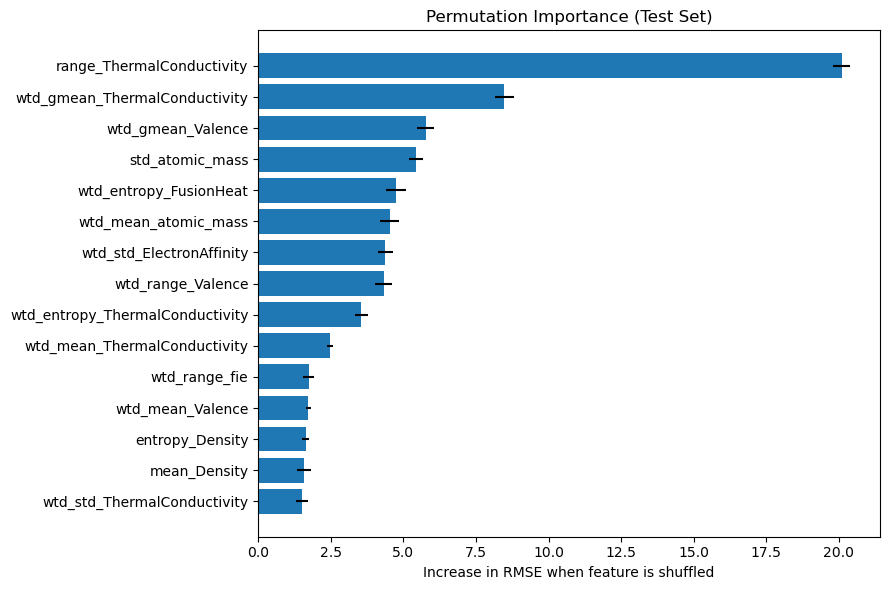


SHAP not installed. Run: pip install shap


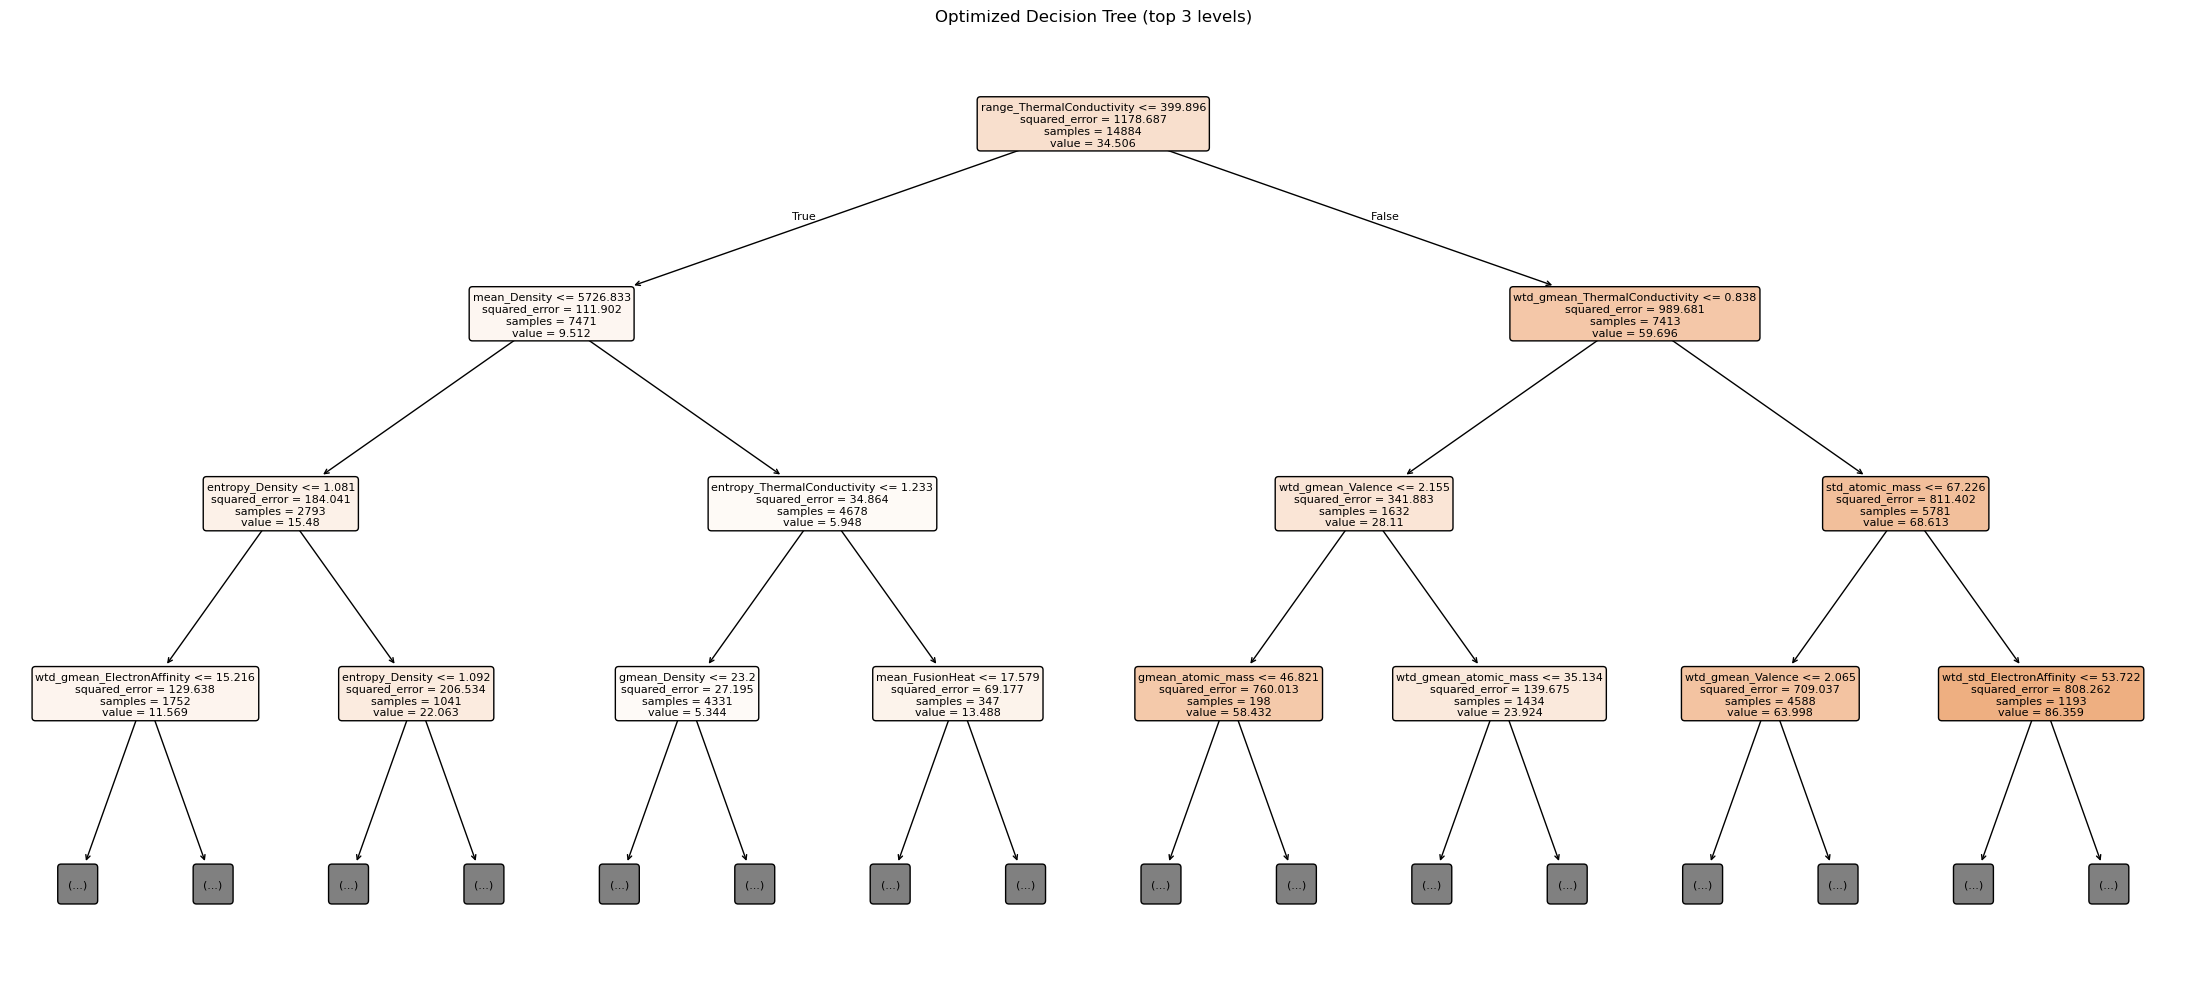


Decision Tree optimization + explainability completed.


In [21]:
# ==========================================================
# 13. EXPLAINABILITY
# ==========================================================

print("\n" + "=" * 60)
print("EXPLAINABILITY")
print("=" * 60)

TOP_N = 15

# ---- 13a. Built-in (impurity-based) feature importance ----
imp = pd.Series(
    dt_optimized.feature_importances_, index=feature_names
).sort_values(ascending=False)

imp.to_csv("DT_Feature_Importance.csv", header=["Importance"])
print("\nTop 10 features (impurity-based):")
print(imp.head(10).round(4).to_string())

plt.figure(figsize=(9, 6))
imp.head(TOP_N)[::-1].plot(kind="barh")
plt.xlabel("Importance")
plt.title("Decision Tree Feature Importance (Impurity-based)")
plt.tight_layout()
plt.savefig("DT_Feature_Importance.png", dpi=300)
plt.show()

# ---- 13b. Permutation importance (on test set) ----
perm = permutation_importance(
    dt_optimized, X_test, y_test,
    n_repeats=10, random_state=SEED, n_jobs=-1,
    scoring="neg_root_mean_squared_error",
)
perm_df = pd.DataFrame({
    "Feature": feature_names,
    "Mean_Importance": perm.importances_mean,
    "Std": perm.importances_std,
}).sort_values("Mean_Importance", ascending=False)

perm_df.to_csv("DT_Permutation_Importance.csv", index=False)
print("\nTop 10 features (permutation):")
print(perm_df.head(10).round(4).to_string(index=False))

top = perm_df.head(TOP_N).iloc[::-1]
plt.figure(figsize=(9, 6))
plt.barh(top["Feature"], top["Mean_Importance"], xerr=top["Std"])
plt.xlabel("Increase in RMSE when feature is shuffled")
plt.title("Permutation Importance (Test Set)")
plt.tight_layout()
plt.savefig("DT_Permutation_Importance.png", dpi=300)
plt.show()

# ---- 13c. SHAP (TreeExplainer) ----
try:
    import shap

    explainer = shap.TreeExplainer(dt_optimized)
    # Subsample test set for speed
    X_shap = X_test.sample(min(1000, len(X_test)), random_state=SEED)
    shap_values = explainer.shap_values(X_shap)

    plt.figure()
    shap.summary_plot(shap_values, X_shap, max_display=TOP_N, show=False)
    plt.tight_layout()
    plt.savefig("DT_SHAP_Summary.png", dpi=300, bbox_inches="tight")
    plt.show()

    plt.figure()
    shap.summary_plot(shap_values, X_shap, plot_type="bar",
                      max_display=TOP_N, show=False)
    plt.tight_layout()
    plt.savefig("DT_SHAP_Bar.png", dpi=300, bbox_inches="tight")
    plt.show()

    print("\nSHAP plots saved.")
except ImportError:
    print("\nSHAP not installed. Run: pip install shap")

# ---- 13d. Tree structure (top levels only, otherwise unreadable) ----
plt.figure(figsize=(22, 10))
plot_tree(
    dt_optimized, max_depth=3, feature_names=feature_names,
    filled=True, rounded=True, fontsize=8,
)
plt.title("Optimized Decision Tree (top 3 levels)")
plt.tight_layout()
plt.savefig("DT_Tree_Structure.png", dpi=300)
plt.show()

print("\nDecision Tree optimization + explainability completed.")

In [25]:
import sys
!{sys.executable} -m pip install shap

   ---------------------------------------- 0.0/751.9 kB ? eta -:--:--
   ---------------------------------------- 0.0/751.9 kB ? eta -:--:--
   ------------- -------------------------- 262.1/751.9 kB ? eta -:--:--
   --------------------------- ------------ 524.3/751.9 kB 1.2 MB/s eta 0:00:01
   ---------------------------------------- 751.9/751.9 kB 1.2 MB/s  0:00:00

   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   ---------------------------------------- 2/2 [shap]



In [26]:
import shap

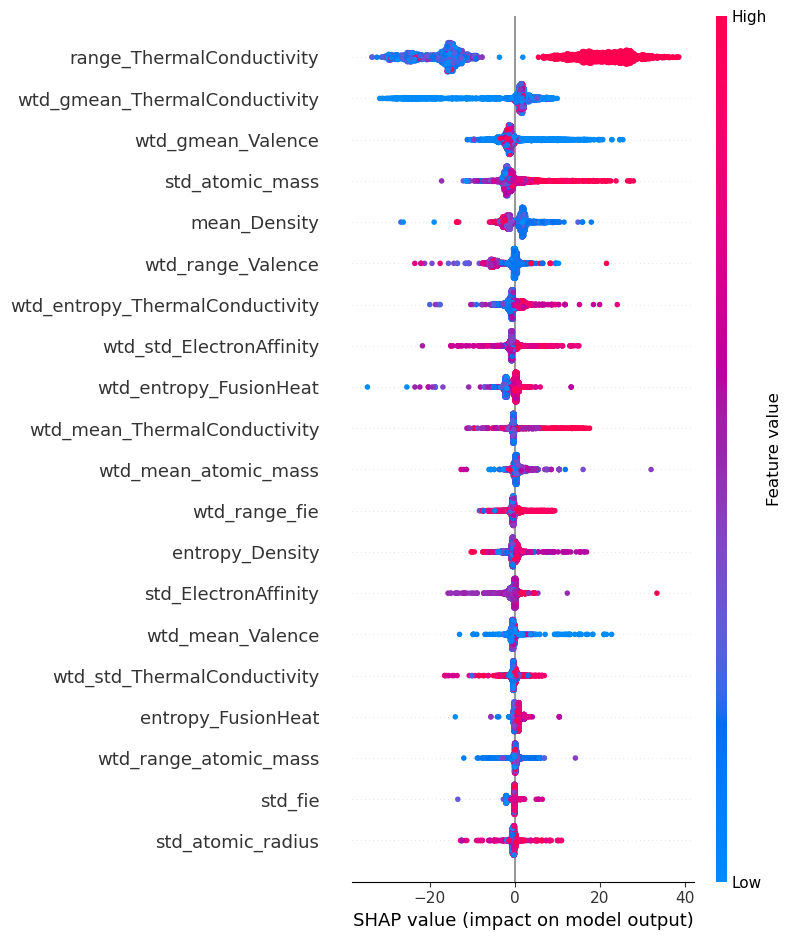

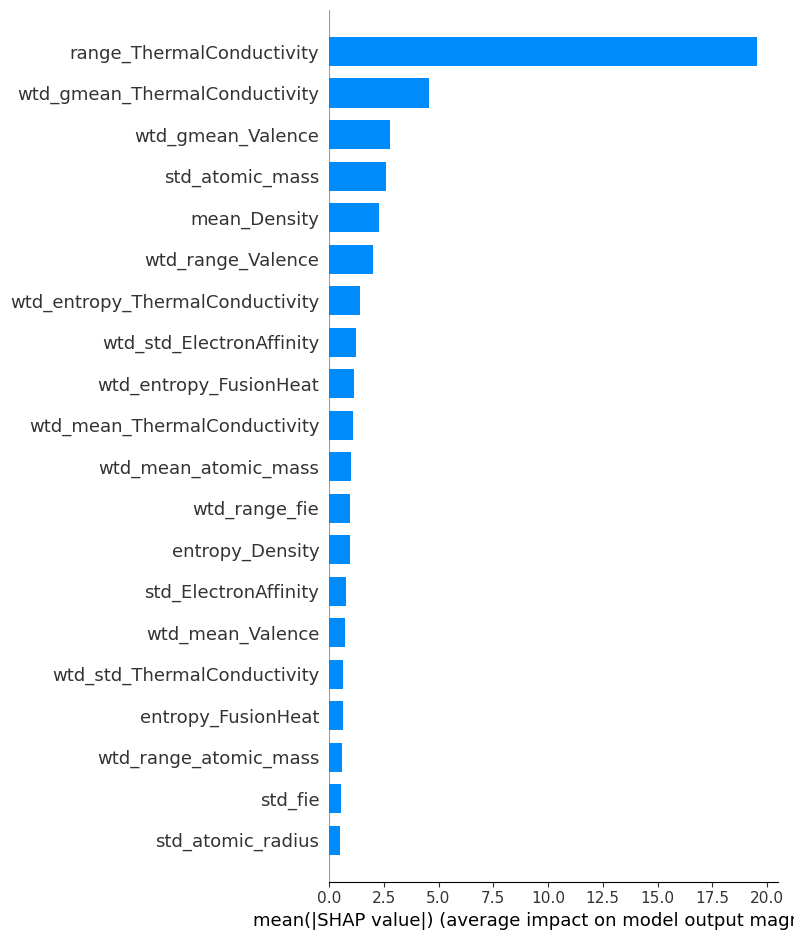

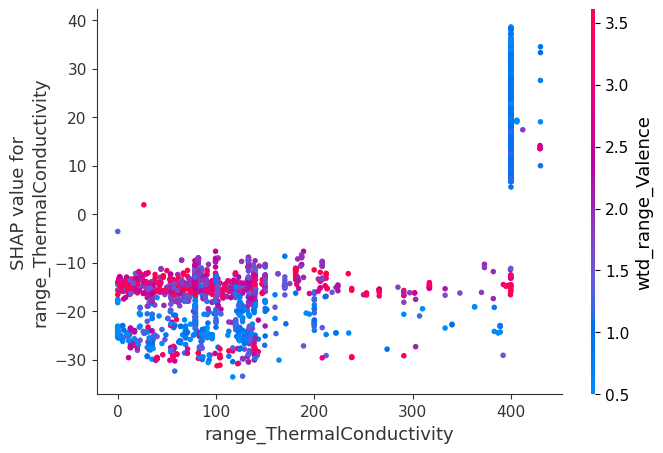

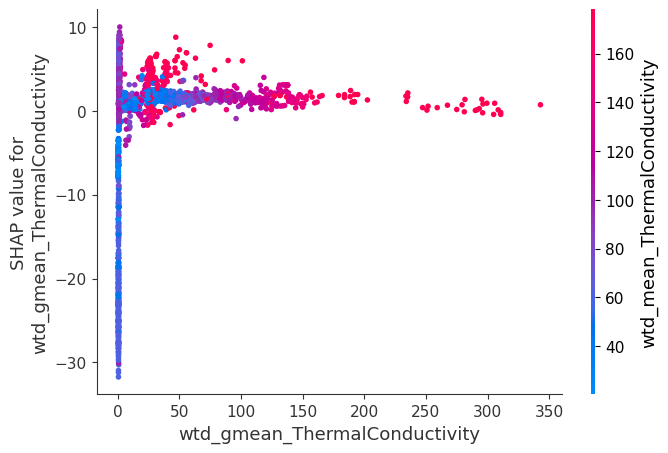

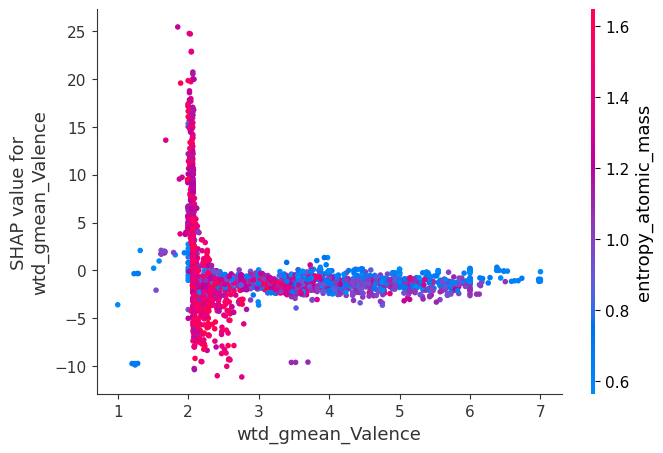

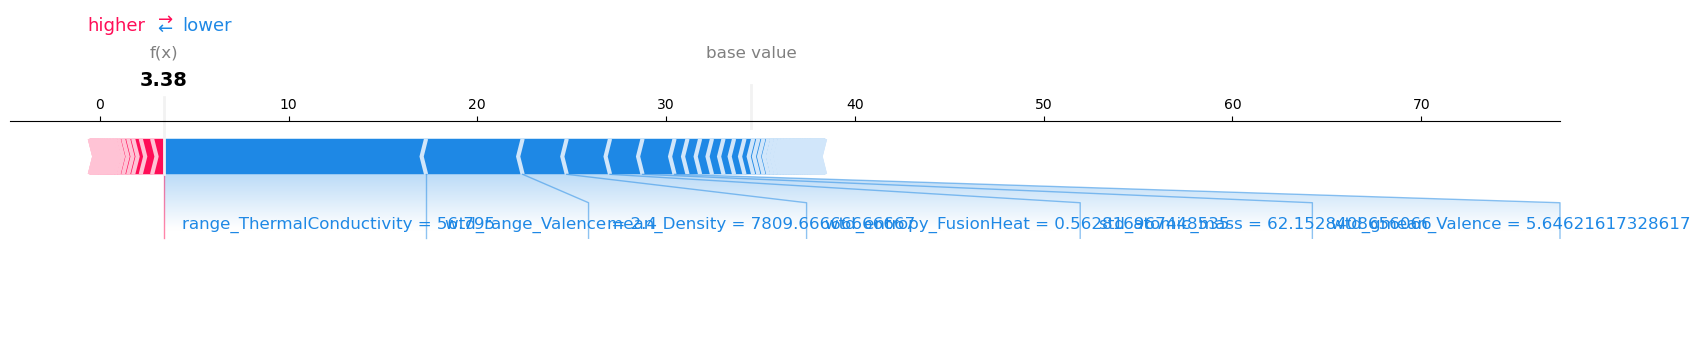

In [31]:
explainer = shap.TreeExplainer(dt_optimized)
shap_values = explainer.shap_values(X_test)

# global importance
shap.summary_plot(shap_values, X_test)
shap.summary_plot(shap_values, X_test, plot_type="bar")

# dependence plots for the top 3 features automatically
import numpy as np
top_idx = np.argsort(np.abs(shap_values).mean(0))[::-1][:3]
for i in top_idx:
    shap.dependence_plot(X_test.columns[i], shap_values, X_test)

# one prediction (first test sample)
shap.force_plot(explainer.expected_value, shap_values[0], X_test.iloc[0], matplotlib=True)

In [29]:
for name, obj in list(globals().items()):
    if "DecisionTree" in str(type(obj)):
        print(name, type(obj))

_ <class 'sklearn.tree._classes.DecisionTreeRegressor'>
dt_baseline <class 'sklearn.tree._classes.DecisionTreeRegressor'>
dt_optimized <class 'sklearn.tree._classes.DecisionTreeRegressor'>
_16 <class 'sklearn.tree._classes.DecisionTreeRegressor'>
